# PHẦN 3 — KỸ THUẬT 3: HOUGH ĐA TỈ LỆ
**Trích xuất đường thẳng với biến đổi Hough Coarse-to-fine và Bỏ phiếu Gradient**
Mã môn: 121036 — Xử lý ảnh và Thị giác máy tính

## 1. Cài đặt 3 hàm cốt lõi

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

def hough_accumulate(edges, delta_deg=1.0, grad_dir=None, grad_delta=10.0):
    """
    Tạo mảng tích lũy Hough. Hỗ trợ bỏ phiếu theo hướng gradient.
    """
    H, W = edges.shape
    D = int(np.ceil(np.sqrt(H**2 + W**2)))
    thetas_deg = np.arange(0, 180, delta_deg)
    thetas_rad = np.deg2rad(thetas_deg)
    rhos = np.arange(-D, D + 1)
    A = np.zeros((len(rhos), len(thetas_deg)), dtype=np.int32)
    
    y_idxs, x_idxs = np.nonzero(edges)
    cos_t = np.cos(thetas_rad)
    sin_t = np.sin(thetas_rad)
    
    for i in range(len(y_idxs)):
        x, y = x_idxs[i], y_idxs[i]
        if grad_dir is not None:
            g_dir = grad_dir[y, x]
            min_angle = (g_dir - grad_delta) % 180
            max_angle = (g_dir + grad_delta) % 180
            if min_angle < max_angle:
                valid_mask = (thetas_deg >= min_angle) & (thetas_deg <= max_angle)
            else:
                valid_mask = (thetas_deg >= min_angle) | (thetas_deg <= max_angle)
            valid_indices = np.where(valid_mask)[0]
        else:
            valid_indices = np.arange(len(thetas_deg))
            
        for t_idx in valid_indices:
            rho = int(np.round(x * cos_t[t_idx] + y * sin_t[t_idx]))
            rho_idx = rho + D
            A[rho_idx, t_idx] += 1
            
    return A, rhos, thetas_deg

def _gaussian_kernel(sigma):
    size = int(6 * sigma + 1)
    if size % 2 == 0: size += 1
    x, y = np.mgrid[-size//2 + 1:size//2 + 1, -size//2 + 1:size//2 + 1]
    g = np.exp(-((x**2 + y**2)/(2.0*sigma**2)))
    return g / g.sum()

def find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0):
    """
    Làm mượt không gian Hough và tìm đỉnh bằng NMS.
    """
    kernel = _gaussian_kernel(smooth_sigma)
    A_smooth = convolve2d(A.astype(float), kernel, mode='same')
    A_nms = np.zeros_like(A_smooth)
    H, W = A_smooth.shape
    
    y_idx, x_idx = np.nonzero(A_smooth > 0.1 * np.max(A_smooth))
    
    for i in range(len(y_idx)):
        y, x = y_idx[i], x_idx[i]
        y_min = max(0, y - nms_radius)
        y_max = min(H, y + nms_radius + 1)
        x_min = max(0, x - nms_radius)
        x_max = min(W, x + nms_radius + 1)
        
        local_window = A_smooth[y_min:y_max, x_min:x_max]
        if A_smooth[y, x] == np.max(local_window):
            A_nms[y, x] = A_smooth[y, x]
            
    flat_indices = np.argsort(A_nms.ravel())[::-1][:n_peaks]
    peak_y, peak_x = np.unravel_index(flat_indices, A_nms.shape)
    
    return peak_y, peak_x

def hough_multiscale(edges, n_peaks, coarse_delta=2.0, fine_delta=0.1):
    """
    Hough đa tỉ lệ: Tìm thô trước, tinh chỉnh sau.
    """
    H, W = edges.shape
    D = int(np.ceil(np.sqrt(H**2 + W**2)))
    
    A_coarse, rhos_coarse, thetas_coarse = hough_accumulate(edges, delta_deg=coarse_delta)
    coarse_y, coarse_x = find_peaks(A_coarse, n_peaks, nms_radius=5, smooth_sigma=2.0)
    
    final_rhos = []
    final_thetas = []
    y_idxs, x_idxs = np.nonzero(edges)
    
    for i in range(n_peaks):
        t_c = thetas_coarse[coarse_x[i]]
        r_c = rhos_coarse[coarse_y[i]]
        
        t_fine_range = np.arange(t_c - coarse_delta, t_c + coarse_delta + fine_delta, fine_delta)
        t_fine_range = t_fine_range % 180 
        r_fine_range = np.arange(r_c - 5, r_c + 6)
        A_fine = np.zeros((len(r_fine_range), len(t_fine_range)), dtype=np.int32)
        
        t_rad_fine = np.deg2rad(t_fine_range)
        cos_t = np.cos(t_rad_fine)
        sin_t = np.sin(t_rad_fine)
        
        for j in range(len(y_idxs)):
            x, y = x_idxs[j], y_idxs[j]
            for k in range(len(t_fine_range)):
                rho = int(np.round(x * cos_t[k] + y * sin_t[k]))
                if r_fine_range[0] <= rho <= r_fine_range[-1]:
                    r_idx = rho - r_fine_range[0]
                    A_fine[r_idx, k] += 1
                    
        best_idx = np.argmax(A_fine)
        best_r_idx, best_t_idx = np.unravel_index(best_idx, A_fine.shape)
        final_rhos.append(r_fine_range[best_r_idx])
        final_thetas.append(t_fine_range[best_t_idx])
        
    return np.array(final_rhos), np.array(final_thetas)

Matplotlib is building the font cache; this may take a moment.


---
## 2. Thí nghiệm minh họa (Kiểm tra góc và đường dài/ngắn)

### Có dùng AI hỗ trợ
Công cụ: Gemini  
Mục đích: Tạo ảnh tổng hợp có nền đen chứa các đoạn thẳng màu trắng với thông số góc chính xác để kiểm thử thuật toán xử lý góc tuần hoàn (0.5°, 179.5°) và các đoạn thẳng rất dài, rất ngắn.  
Prompt:
> Viết đoạn code Python sử dụng thư viện cv2 và numpy để tạo ra một bức ảnh nền đen (zeros) kích thước 256x256. Vẽ lên đó các đoạn thẳng màu trắng với thông số sau: một đường thẳng đứng, một đường nằm ngang, một đoạn cực ngắn, một đoạn cực dài, và 2 đường có góc xấp xỉ 0 độ và 180 độ (ví dụ 0.5 độ và 179.5 độ). Hiển thị ảnh.

Đã sửa lại những gì: Chuyển đổi cách sinh ảnh từ dùng cv2 sang thuần numpy theo yêu cầu để tránh phụ thuộc thư viện ngoài.

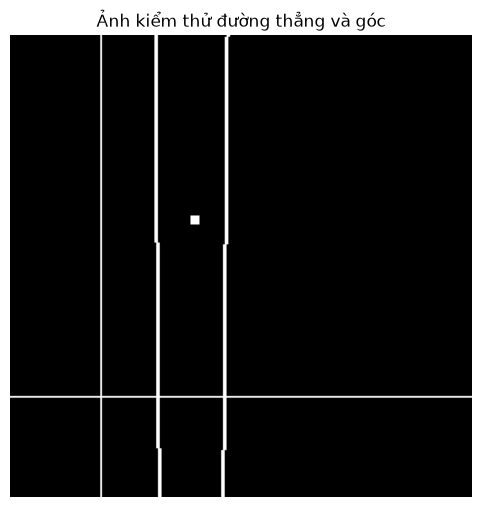

In [8]:
import numpy as np

# Sinh bộ ảnh test
H_test, W_test = 256, 256
import matplotlib.pyplot as plt

img_lines = np.zeros((H_test, W_test), dtype=np.uint8)
yy, xx = np.mgrid[0:H_test, 0:W_test]

# 1. Đường thẳng đứng (x = 50)
img_lines[:, 50] = 255

# 2. Đường nằm ngang (y = 200)
img_lines[200, :] = 255

# 3. Đoạn cực ngắn
img_lines[100:105, 100:105] = 255

# 4. Góc xấp xỉ 0 độ (0.5 độ)
theta_0_5 = np.deg2rad(0.5)
rho_0_5 = 120
dist_0_5 = np.abs(xx * np.cos(theta_0_5) + yy * np.sin(theta_0_5) - rho_0_5)
img_lines[dist_0_5 < 1.0] = 255

# 5. Góc xấp xỉ 180 độ (179.5 độ)
theta_179_5 = np.deg2rad(179.5)
rho_179_5 = -80
dist_179_5 = np.abs(xx * np.cos(theta_179_5) + yy * np.sin(theta_179_5) - rho_179_5)
img_lines[dist_179_5 < 1.0] = 255

plt.figure(figsize=(6,6))
plt.imshow(img_lines, cmap='gray')
plt.title('Ảnh kiểm thử đường thẳng và góc')
plt.axis('off')
plt.show()

In [9]:
# Chạy thử nghiệm hàm
print("=== Chạy kiểm thử Hough Multiscale ===")
rhos, thetas = hough_multiscale(img_lines, n_peaks=5)
for i in range(len(rhos)):
    print(f"Đỉnh {i+1}: rho = {rhos[i]:.2f}, theta = {thetas[i]:.2f} độ")

=== Chạy kiểm thử Hough Multiscale ===
Đỉnh 1: rho = 81.00, theta = 0.00 độ
Đỉnh 2: rho = 120.00, theta = 0.40 độ
Đỉnh 3: rho = -77.00, theta = 178.00 độ
Đỉnh 4: rho = 200.00, theta = 89.90 độ
Đỉnh 5: rho = -117.00, theta = 178.00 độ
